In [79]:
#%matplotlib inline
%matplotlib widget
%precision 8
import numpy
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.pyplot import cm
from tqdm import tqdm 

Before you turn this problem in, make sure everything runs as expected. First, restart the kernel (in the menubar, select Kernel $\rightarrow$ Restart) and then run all cells (in the menubar, select Cell $\rightarrow$ Run All).

Make sure you fill in any place that says YOUR CODE HERE or "YOUR ANSWER HERE", as well as your name and collaborators below:

# HW 3: BVP Problems II

## Question 1

Consider the two-dimensional Poisson problem defined as
$$
    \nabla^2 u = f(x,y) ~~~~ \Omega = [0, 1] \times [0, 1]
$$
with Dirichlet boundary conditions $u(x,y)|_{\partial \Omega} = 0$.

Note that the notation $\partial \Omega$ often refers to the boundary of $\Omega$ and $u(x,y)|_{\partial \Omega}$ the solution evaluted at the boundary.

**(a)** [5] If we wanted to consider solutions of the form
$$
    u(x,y) = (y^3 - y) (\cos(2 \pi x) - 1)
$$
what should we require $f(x,y)$ to be?  Is this consistent with the boundary conditions?  This technique of assuming a solution and finding what forcing function would give you that solution is called the **Method of Manufactured Solutions** and is a good way to test numerical methods.

**Answer**:

if $u(x,y)=(y^3-y)(\cos(2\pi x)-1)$, then $\nabla u=(u_x,u_y)=(-2\pi(y^3-y)\sin(2\pi x),(3y^2-1)(\cos(2\pi x)-1)$,

$$\Delta u = u_{xx}+u_{yy}=-4 \pi ^2 y \left(y^2-1\right) \cos (2 \pi  x)-12 y \sin ^2(\pi x)=f(x,y)$$

let $y=0$ or $y=1$, we have $u(x,0)=u(x,1)=0$, let $x=0$ or $x=1$, we have $u(1,0)=u(0,0)=0$, hence $u(x,y)$ is consistent with the boundary conditions, i.e. $u(x,y)|_{\partial \Omega}=0$.

**(b)** [10] Implement a finite difference method for the problem above with grid spacing $\Delta x = \Delta y$ using a 9-point Laplacian.

In [153]:
# Suggested modules to use to construct matrix A
# You do not have to use these, they just may be helpful
import scipy.sparse as sparse
import scipy.sparse.linalg as linalg

def solve_9point(m, f):
    h = 1 / (m - 1)

    def flat(i, j):
        return i * m + j

    def coord(i, j):
        return f(i / (m - 1), j / (m - 1))

    def get_mat():
        N = 9 * (m - 2) * (m - 2)

        Is_mid = np.array([i // 9 for i in range(N)])
        Js_mid = np.array([list(map(lambda x: flat(x[0], x[1]), 
            [[i - 1, j], [i + 1, j], [i, j - 1], [i, j + 1], [i - 1, j - 1], [i - 1, j + 1], [i + 1, j - 1], [i + 1, j + 1], [i, j]]
            )) for i in range (1, m - 1) for j in range(1, m - 1)]).flatten()
        data_mid = np.array([[2 / (3 * h ** 2), 2 / (3 * h ** 2), 2 / (3 * h ** 2), 2 / (3 * h ** 2),
            1 / (6 * h ** 2), 1 / (6 * h ** 2), 1 / (6 * h ** 2), 1 / (6 * h ** 2), - 10 / (3 * h ** 2)] for _ in range((m - 2) * (m - 2))]).flatten()
        bs_mid = np.array([coord(i, j) for i in range (1, m - 1) for j in range(1, m - 1)])

        Is_add = np.array([i for i in range(Is_mid[-1] + 1, Is_mid[-1] + 4 * m - 3)])

        Js_left = np.array(list(map(lambda x: flat(x[0], x[1]), [[j, 0] for j in range(m)])))
        Js_right = np.array(list(map(lambda x: flat(x[0], x[1]), [[j, m - 1] for j in range(m)])))
        Js_top = np.array(list(map(lambda x: flat(x[0], x[1]), [[0, j] for j in range(1, m - 1)])))
        Js_bottom = np.array(list(map(lambda x: flat(x[0], x[1]), [[m - 1, j] for j in range(1, m - 1)])))

        data_add = np.array([1 / (h ** 2)] * (4 * m - 4))
        bs_add = np.array([0] * (4 * m - 4))

        # concat
        Is = np.concatenate([Is_mid, Is_add])
        Js = np.concatenate([Js_mid, Js_left, Js_right, Js_top, Js_bottom])
        data = np.concatenate([data_mid, data_add])
        bs = np.concatenate([bs_mid, bs_add])

        # mat
        mat = sparse.coo_matrix((data, (Is, Js)), dtype=np.float64).tocsc()
        return mat, bs

    mat, bs = get_mat()
    sol = linalg.spsolve(mat, bs).reshape((m, m)).transpose()
    xs = np.linspace(0, 1, m)
    ys = np.linspace(0, 1, m)

    return xs, ys, sol


Text(0.5, 0.92, 'Absolute error')

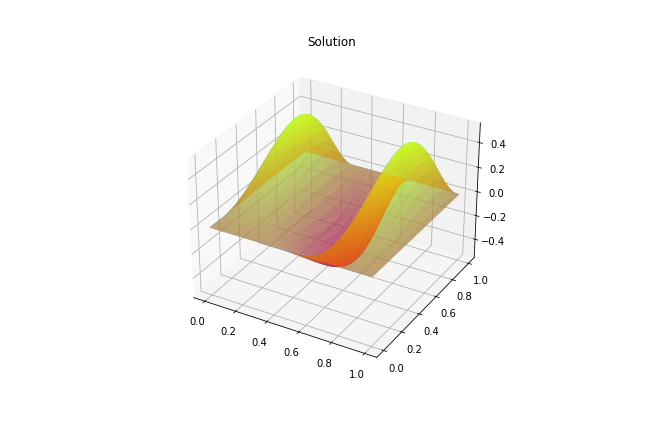

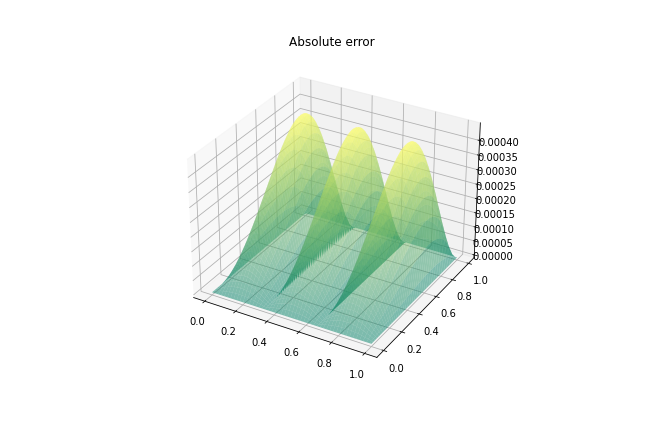

In [154]:
f = lambda x, y: -(20.0 * y**3 + 9.0 * numpy.pi**2 * (y - y**5)) * numpy.sin(3.0 * numpy.pi * x)
u_true = lambda x, y: (y - y**5) * numpy.sin(3.0 * numpy.pi * x)

x, y, U = solve_9point(100, f)
X, Y = numpy.meshgrid(x, y)

U_true = u_true(X, Y)

fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(111, projection='3d')
surf = ax.plot_surface(X, Y, U, linewidth=0, cmap=cm.winter, alpha=0.5, antialiased=True)
surf2 = ax.plot_surface(X, Y, U_true, linewidth=0, cmap=cm.autumn, alpha=0.5, antialiased=True)
ax.set_title("Solution")
# fig.show()

fig2 = plt.figure(figsize=(9,6))
ax2 = fig2.add_subplot(111, projection='3d')
err_surf = ax2.plot_surface(X, Y, np.abs(U - U_true), linewidth=0, cmap=cm.summer, alpha=0.5, antialiased=True)
ax2.set_title("Absolute error")
# fig2.show()

In [62]:
error = numpy.linalg.norm((x[1] - x[0]) * (u_true(X, Y) - U), ord=1)
print(error)
assert error < 1e-3
print("Success!")

0.0002759876729779913
Success!


**(c)** [15] Show that the 9-point Laplacian can be written as a 5-point Laplacian **plus** a finite difference approximation of $\frac{1}{6}\Delta x^2 u_{xxyy} + \mathcal O(\Delta x^4)$.  Be explicit about the derivation of the truncation error derivation.

Firstly, we can write out the following central finite difference approximations along $x$ axis ('' for differentiation along $x$):

$$\dfrac{1}{\Delta x^2}(u_{i+1,j+1}-2u_{i,j+1}+u_{i-1,j+1})=u_{i,j+1}''+\mathcal{O}(\Delta x^2)\quad (1)$$

$$\dfrac{1}{\Delta x^2}(u_{i+1,j}-2u_{i,j}+u_{i-1,j})=u_{i,j}''+\mathcal{O}(\Delta x^2)\quad (2)$$

$$\dfrac{1}{\Delta x^2}(u_{i+1,j-1}-2u_{i,j-1}+u_{i-1,j-1})=u_{i,j-1}''+\mathcal{O}(\Delta x^2)\quad (3)$$

(1)+(3)-2(2), we have

$$\dfrac{1}{\Delta x^2\Delta y^2}(u_{i+1,j+1}-2u_{i,j+1}+u_{i-1,j+1}+u_{i+1,j-1}-2u_{i,j-1}+u_{i-1,j-1}-2u_{i+1,j}+4u_{i,j}-2u_{i-1,j})\\
=\dfrac{u_{i,j+1}''-2u_{i,j}''+u_{i,j-1}''}{\Delta y^2}+\mathcal{O}(\Delta x^2)=(u_{xxyy})_{i,j}+\mathcal{O}(\Delta x^2+\Delta y^2)\quad (4)$$

a typical 9-point Laplacian formula is

$$\nabla_9^2u_{ij}=\frac{1}{6h^2}[4u_{i-1,j}+4u_{i+1,j}+4u_{i,j-1}+4u_{i,j+1}+u_{i-1,j-1}+u_{i-1,j+1}+u_{i+1,j-1}+u_{i+1,j+1}-20u_{ij}]\quad (5)$$

let $h=\Delta x=\Delta y$, consider $(5)-(4)\dfrac{\Delta x^2}{6}$, we have

$$\nabla_9^2u_{ij}=\dfrac{1}{6}\Delta x^2(u_{xxyy})_{i,j}+\mathcal{O}(\Delta x^4)+\dfrac{1}{h^2}(u_{i-1,j}+u_{i+1,j}+u_{i,j-1}+u_{i,j+1}-4u_{i,j})$$

note that $$\dfrac{1}{h^2}(u_{i-1,j}+u_{i+1,j}+u_{i,j-1}+u_{i,j+1}-4u_{i,j})$$ is exactly the formula for 5-point Laplacian, therefore the 9-point Laplacian can be written as a 5-point Laplacian **plus** a finite difference approximation of $\frac{1}{6}\Delta x^2 u_{xxyy} + \mathcal O(\Delta x^4)$.

**Remark**: (1)(2)(3) is derived from the fact

$$f(x+h)=f(x)+f'(x)h+\dfrac{1}{2}f''(x)h^2+\dfrac{1}{6}f'''(x)h^3+O(h^4)$$
$$f(x-h)=f(x)-f'(x)h+\dfrac{1}{2}f''(x)h^2-\dfrac{1}{6}f'''(x)h^3+O(h^2)$$

$$\Rightarrow \dfrac{f(x+h)-2f(x)+f(x-h)}{h^2}=f''(x)+O(h^2)$$

**(d)** [10] Modify your function to use the trick introduced in class that will cause the 9-point Laplacian stencil to become 4th order accurate.  Show that this is true via a convergence study.

Transform the RHS:

$$
    f_{ij} = f(x_i, y_j) + \frac{\Delta x^2}{12} \nabla^2 f(x_i, y_j)
$$

In [65]:
f_lap = lambda x, y: 3 * y * (-40 + 120 * np.pi ** 2 * y ** 2-27 * np.pi ** 4 * (y ** 4 - 1)) * np.sin(3 * np.pi * x)

def solve_9point_2(m, f, f_lap):
    h = 1 / (m - 1)

    def flat(i, j):
        return i * m + j

    def coord(i, j):
        return f(i / (m - 1), j / (m - 1)) + h ** 2 * f_lap(i / (m - 1), j / (m - 1)) / 12

    def get_mat():
        N = 9 * (m - 2) * (m - 2)

        Is_mid = np.array([i // 9 for i in range(N)])
        Js_mid = np.array([list(map(lambda x: flat(x[0], x[1]), 
            [[i - 1, j], [i + 1, j], [i, j - 1], [i, j + 1], [i - 1, j - 1], [i - 1, j + 1], [i + 1, j - 1], [i + 1, j + 1], [i, j]]
            )) for i in range (1, m - 1) for j in range(1, m - 1)]).flatten()
        data_mid = np.array([[2 / (3 * h ** 2), 2 / (3 * h ** 2), 2 / (3 * h ** 2), 2 / (3 * h ** 2),
            1 / (6 * h ** 2), 1 / (6 * h ** 2), 1 / (6 * h ** 2), 1 / (6 * h ** 2), - 10 / (3 * h ** 2)] for _ in range((m - 2) * (m - 2))]).flatten()
        bs_mid = np.array([coord(i, j) for i in range (1, m - 1) for j in range(1, m - 1)])

        Is_add = np.array([i for i in range(Is_mid[-1] + 1, Is_mid[-1] + 4 * m - 3)])

        Js_left = np.array(list(map(lambda x: flat(x[0], x[1]), [[j, 0] for j in range(m)])))
        Js_right = np.array(list(map(lambda x: flat(x[0], x[1]), [[j, m - 1] for j in range(m)])))
        Js_top = np.array(list(map(lambda x: flat(x[0], x[1]), [[0, j] for j in range(1, m - 1)])))
        Js_bottom = np.array(list(map(lambda x: flat(x[0], x[1]), [[m - 1, j] for j in range(1, m - 1)])))

        data_add = np.array([1 / (h ** 2)] * (4 * m - 4))
        bs_add = np.array([0] * (4 * m - 4))

        # concat
        Is = np.concatenate([Is_mid, Is_add])
        Js = np.concatenate([Js_mid, Js_left, Js_right, Js_top, Js_bottom])
        data = np.concatenate([data_mid, data_add])
        bs = np.concatenate([bs_mid, bs_add])

        # mat
        mat = sparse.coo_matrix((data, (Is, Js)), dtype=np.float64).tocsc()
        return mat, bs

    mat, bs = get_mat()
    sol = linalg.spsolve(mat, bs).reshape((m, m)).transpose()
    xs = np.linspace(0, 1, m)
    ys = np.linspace(0, 1, m)

    return xs, ys, sol


Text(0.5, 0.92, 'Absolute error')

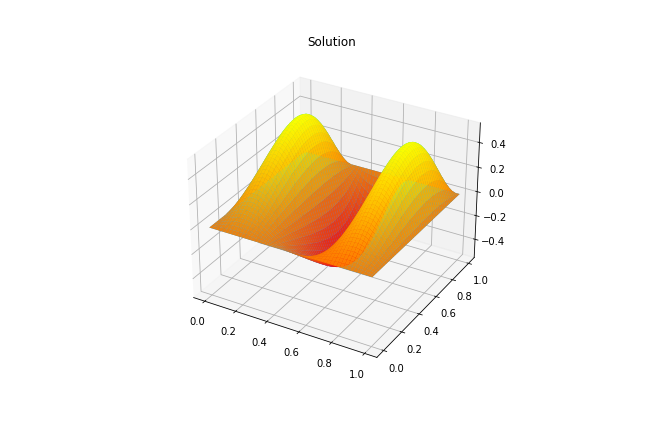

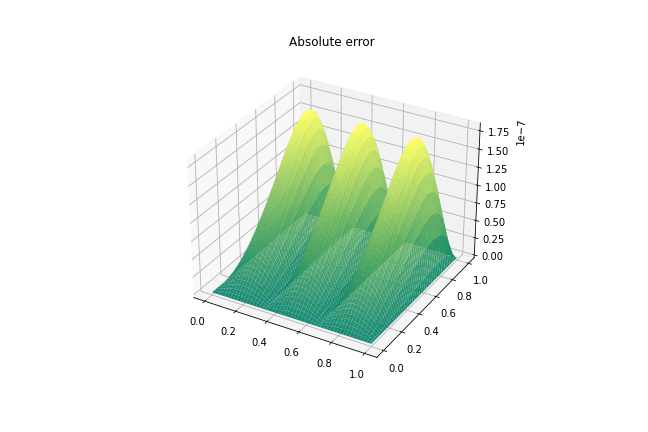

In [69]:
x, y, U = solve_9point_2(100, f, f_lap)
X, Y = numpy.meshgrid(x, y)

U_true = u_true(X, Y)

fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(111, projection='3d')
surf = ax.plot_surface(X, Y, U, linewidth=0, cmap=cm.winter, alpha=0.9, antialiased=True)
surf2 = ax.plot_surface(X, Y, U_true, linewidth=0, cmap=cm.autumn, alpha=0.9, antialiased=True)
ax.set_title("Solution")
# fig.show()

fig2 = plt.figure(figsize=(9,6))
ax2 = fig2.add_subplot(111, projection='3d')
err_surf = ax2.plot_surface(X, Y, np.abs(U - U_true), linewidth=0, cmap=cm.summer, alpha=0.9, antialiased=True)
ax2.set_title("Absolute error")
# fig2.show()

In [70]:
error = numpy.linalg.norm((x[1] - x[0]) * (u_true(X, Y) - U), ord=1)
print(error)

1.0418193606352378e-07


Now the error is about $10^{-7}$.

## Question 2

Let us consider some modifications to the Gauss-Seidel method we discussed and when one version might be better than the other.

**(a)** [5] The Gauss-Seidel method for the discretization of $u''(x) = f(x)$
takes the form 
$$
    U_i^{(k+1)} = \frac{1}{2} (U_{i+1}^{(k)} + U_{i-1}^{(k+1)}) - f(x_i) \frac{\Delta x^2}{2}
$$
if we assume we are marching forwards across the grid,
for $i=1,~2,~\ldots,~m$.  We can also define a *backwards Gauss-Seidel
method* by setting
$$
    U_i^{(k+1)} = \frac{1}{2} (U_{i+1}^{(k+1)} + U_{i-1}^{(k)}) - f(x_i) \frac{\Delta x^2}{2}
$$
Show that this is a matrix splitting method of the type described in the lecture notes and what the splitting is.

For the first formula, we can rewrite it as

$$\begin{bmatrix}
a_{11} & a_{12} & a_{13} & a_{14} & \cdots & a_{1n}\\
-\dfrac{1}{2} & 1 & 0 & 0 & \cdots & 0\\
0 & -\dfrac{1}{2} & 1 & 0 & \cdots & 0\\
\vdots & \vdots & \vdots & \vdots & \ddots & 0\\
a_{m1} & a_{m2} & a_{m3} & \cdots & a_{mn}
\end{bmatrix}U^{k+1}=
\begin{bmatrix}
0 & \dfrac{1}{2} & 0 & 0 & \cdots & 0\\
0 & 0 & \dfrac{1}{2} & 0 & \cdots & 0\\
0 & 0 & 0 & \dfrac{1}{2} & \cdots & 0\\
\vdots & \vdots & \vdots & \vdots & \ddots & 0\\
b_{m1} & b_{m2} & b_{m3} & \cdots & b_{mn}
\end{bmatrix}U^{k}-\dfrac{\Delta x^2}{2}
\begin{bmatrix}
f(x_1)\\ f(x_2) \\ f(x_3) \\ \vdots\\ f(x_m)
\end{bmatrix}$$

For the second formula, similarly, we have

$$\begin{bmatrix}
a_{11} & a_{12} & a_{13} & a_{14} & \cdots & a_{1n}\\
0 & 1 & -\dfrac{1}{2} & 0 & \cdots & 0\\
0 & 0 & 1 & -\dfrac{1}{2} & \cdots & 0\\
\vdots & \vdots & \vdots & \vdots & \ddots & 0\\
a_{m1} & a_{m2} & a_{m3} & \cdots & a_{mn}
\end{bmatrix}U^{k+1}=
\begin{bmatrix}
0 & \dfrac{1}{2} & 0 & 0 & \cdots & 0\\
0 & 0 & \dfrac{1}{2} & 0 & \cdots & 0\\
0 & 0 & 0 & \dfrac{1}{2} & \cdots & 0\\
\vdots & \vdots & \vdots & \vdots & \ddots & 0\\
b_{m1} & b_{m2} & b_{m3} & \cdots & b_{mn}
\end{bmatrix}U^{k}-\dfrac{\Delta x^2}{2}
\begin{bmatrix}
f(x_1)\\ f(x_2) \\ f(x_3) \\ \vdots\\ f(x_m)
\end{bmatrix}$$

i.e. $AU^{m+1}=BU^{k}+k$. Therefore this is a matrix splitting method. Here we left the first and last row undetermined, since they're related to boundary conditions.

**(b)** [5] Implement the backwards Gauss-Seidel method and show that the convergence is at the same rate as the forward version (do this computationally, you do not need to do this analytically).  Use the same expected iteration count as with the forwards method.

In [98]:
# assume 

def solve_BGS(a, b, alpha, beta, m, f, forward=True, n=-1):

    e = 1e-7
    k = 2 * np.log(e) / np.log(0.5) # approxmated rho

    # Descretization
    x_bc = numpy.linspace(a, b, m + 2)
    delta_x = (b - a) / (m + 1)

    # Expected iterations needed
    iterations_GS = int(2.0 * numpy.log(delta_x) / numpy.log(1.0 - numpy.pi**2 * delta_x**2)) if n < 0 else n

    # Initial guess for iterations
    Us = numpy.zeros((iterations_GS, m + 2))
    Us[:, 0] = np.ones(iterations_GS) * alpha
    Us[:, -1] = np.ones(iterations_GS) * beta

    step_size_GS = numpy.zeros(iterations_GS)
    for k in tqdm(range(1, iterations_GS)):
        if forward:
            for i in range(1, m + 1):
                Us[k, i] = 0.5 * (Us[k - 1, i + 1] + Us[k, i - 1]) - f(x_bc[i]) * delta_x**2 / 2.0
        else:
            for i in range(m, 0, -1):
                Us[k, i] = 0.5 * (Us[k, i + 1] + Us[k - 1, i - 1]) - f(x_bc[i]) * delta_x**2 / 2.0
        step_size_GS[k] = numpy.linalg.norm(Us[k, :] - Us[k - 1, :], ord=2)

    return x_bc, Us[-1, :], Us, step_size_GS

In [88]:
# Problem setup
a = 0.0
b = 1.0
alpha = 0.0
beta = 3.0
f = lambda x: numpy.exp(x)
u_true = lambda x: (4.0 - numpy.exp(1.0)) * x - 1.0 + numpy.exp(x)

x, U, Us, steps = solve_BGS(a, b, alpha, beta, 150, f)
x2, U2, Us2, steps2 = solve_BGS(a, b, alpha, beta, 150, f, False)
error = numpy.linalg.norm((x[1] - x[0]) * (u_true(x) - U), ord=1)
error2 = numpy.linalg.norm((x[1] - x[0]) * (u_true(x) - U), ord=1)
print("Forward error: ", error)
print("Backward error: ", error2)
assert(error < 1e-4)
assert(error2 < 1e-4)
print("Success!")

# errors
errs = np.array([numpy.linalg.norm((x[1] - x[0]) * (u_true(x) - u), ord=1) for u in Us])
errs2 = np.array([numpy.linalg.norm((x[1] - x[0]) * (u_true(x) - u), ord=1) for u in Us2])

100%|██████████| 23176/23176 [00:05<00:00, 3960.67it/s]


Forward error:  4.76813996657345e-05
Backward error:  4.76813996657345e-05
Success!


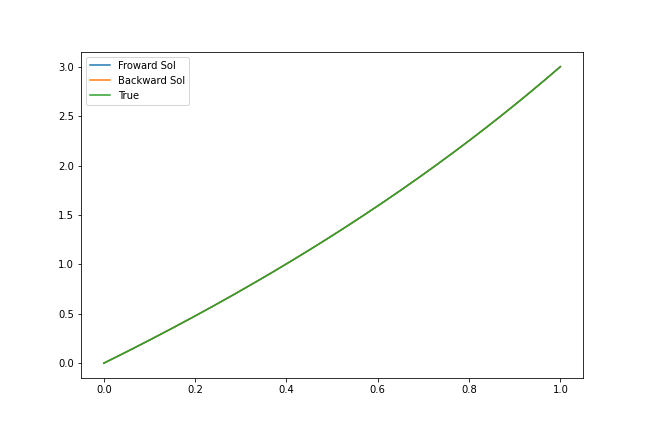

In [97]:
fig = plt.figure(figsize=(9,6))
plt.plot(x, U, label="Froward Sol")
plt.plot(x, U2, label="Backward Sol")
plt.plot(x, u_true(x), label="True")
plt.legend()
plt.show()

Text(0.5, 1.0, 'Step sizes')

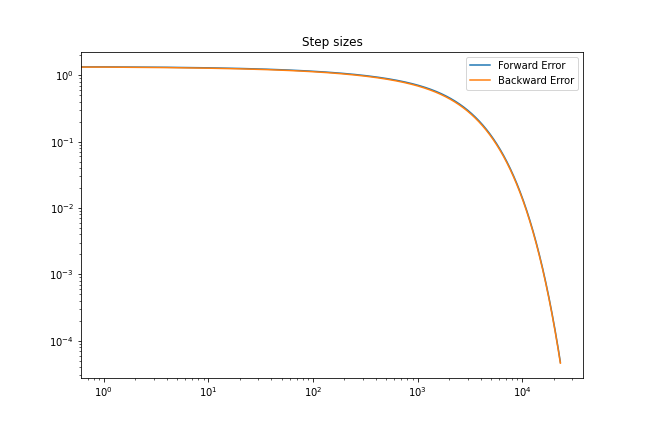

In [94]:
fig = plt.figure(figsize=(9, 6))
# plt.plot(steps, label="Forward Step Size")
# plt.plot(steps2, label="Backward Step Size")
plt.plot(errs, label="Forward Error")
plt.plot(errs2, label="Backward Error")
plt.xscale('log')
plt.yscale('log')
plt.legend()
plt.title("Step sizes and errors")
# plt.show()

As we can see from the graph, they converge in the same speed.

**(c)** [10] Modify the code so that it solves the steady-state problem
$$
    \epsilon u''(x) - u'(x) = f(x)
$$
we had before with the same boundaries and $f(x) = -1$.  This time however use the one-sided approximation to the first derivative
$$
    \frac{U_i - U_{i-1}}{\Delta x}.
$$
Test both forward and backward Gauss-Seidel for the resulting linear system.  Use the value $\epsilon = 0.01$, $m = 100$, and a maximum number of iterations of $250$.  Plot the convergence of both approaches.

**Answer:**

Discretized formula

$$\varepsilon \dfrac{U_{i+1}-2U_i+U_{i-1}}{\Delta x^2}-\dfrac{U_i-U_{i-1}}{\Delta x}=f(x_i)$$

To Gauss-Seidel form (Forward)

$$U_i^{k+1}=\dfrac{1}{2\varepsilon+\Delta x}\left[\varepsilon U_{i+1}^{(k)}+(\varepsilon +\Delta x) U_{i-1}^{k+1}-f(x_i)\Delta x^2\right]$$

(Backward)

$$U_i^{k+1}=\dfrac{1}{2\varepsilon+\Delta x}\left[\varepsilon U_{i+1}^{(k+1)}+(\varepsilon +\Delta x) U_{i-1}^{k}-f(x_i)\Delta x^2\right]$$

In [131]:
def solve_BGS_2(a, b, alpha, beta, e, m, f, forward=True, n=-1):

    # Descretization
    x_bc = numpy.linspace(a, b, m + 2)
    delta_x = (b - a) / (m + 1)

    # Expected iterations needed
    iterations_GS = int(2.0 * numpy.log(delta_x) / numpy.log(1.0 - numpy.pi**2 * delta_x**2)) if n < 0 else n

    # Initial guess for iterations
    Us = numpy.zeros((iterations_GS, m + 2))
    Us[:, 0] = np.ones(iterations_GS) * alpha
    Us[:, -1] = np.ones(iterations_GS) * beta

    step_size_GS = numpy.zeros(iterations_GS)
    for k in tqdm(range(1, iterations_GS)):
        if forward:
            for i in range(1, m + 1):
                Us[k, i] = (e * Us[k - 1, i + 1] + (e + delta_x) * Us[k, i - 1] + 1 * delta_x ** 2) / (2 * e + delta_x)
        else:
            for i in range(m, 0, -1):
                Us[k, i] = (e * Us[k, i + 1] + (e + delta_x) * Us[k - 1, i - 1] + 1 * delta_x ** 2) / (2 * e + delta_x)
        step_size_GS[k] = numpy.linalg.norm(Us[k, :] - Us[k - 1, :], ord=2)

    return x_bc, Us[-1, :], Us, step_size_GS

In [133]:
a = 0.0
b = 1.0
alpha = 1.0
beta = 3.0
epsilon = 0.01
u_true = lambda x: alpha + x + (beta - alpha - 1.0) * (numpy.exp(x / epsilon) - 1.0) / (numpy.exp(1.0 / epsilon) - 1.0)

f = lambda x: -1.0

x, U, Us, steps = solve_BGS_2(a, b, alpha, beta, epsilon, 100, f, n=251)
x2, U2, Us2, steps2 = solve_BGS_2(a, b, alpha, beta, epsilon, 100, f, False, n=251)
error = numpy.linalg.norm((x[1] - x[0]) * (u_true(x) - U), ord=1)
error2 = numpy.linalg.norm((x[1] - x[0]) * (u_true(x) - U), ord=1)
print("Forward error: ", error)
print("Backward error: ", error2)

# errors
errs = np.array([numpy.linalg.norm((x[1] - x[0]) * (u_true(x) - u), ord=1) for u in Us])
errs2 = np.array([numpy.linalg.norm((x[1] - x[0]) * (u_true(x) - u), ord=1) for u in Us2])

100%|██████████| 250/250 [00:00<00:00, 12783.46it/s]

Forward error:  0.004146153838181165
Backward error:  0.004146153838181165


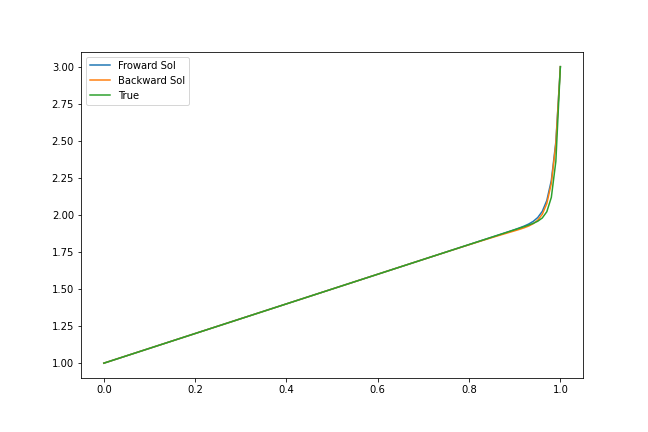

In [134]:
fig = plt.figure(figsize=(9,6))
plt.plot(x, U, label="Froward Sol")
plt.plot(x, U2, label="Backward Sol")
plt.plot(x, u_true(x), label="True")
plt.legend()
plt.show()

Text(0.5, 1.0, 'Step sizes and errors')

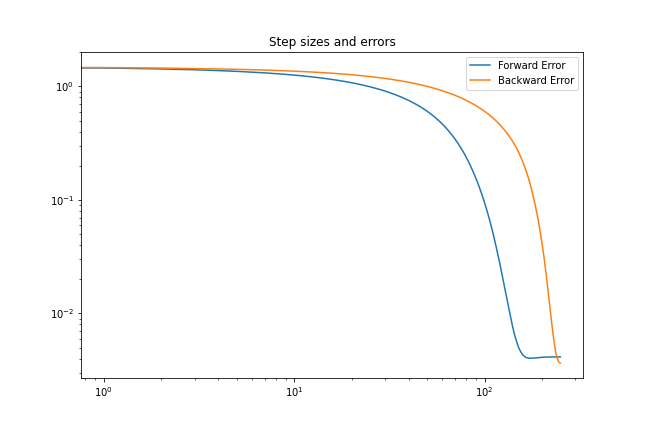

In [135]:
fig = plt.figure(figsize=(9, 6))
# plt.plot(steps, label="Forward Step Size")
# plt.plot(steps2, label="Backward Step Size")
plt.plot(errs, label="Forward Error")
plt.plot(errs2, label="Backward Error")
plt.xscale('log')
plt.yscale('log')
plt.legend()
plt.title("Step sizes and errors")

**(d)** [5] Explain intuitively why sweeping in one direction works so much better than
in the other.

**Hint**: Note that this equation is the steady equation for an advection-diffusion PDE 
$$
    u_t(x,t) + u_x(x,t) = \epsilon u_{xx}(x,t) - f(x).
$$  
You might consider how the methods behave in the case $\epsilon = 0$.

**Answer:**

From the hint we know that this equation is the steady equation for an advection-diffusion PDE, in this problem $f(x)=-1$ is the external input. Hence there is a direction in which $u$ tends to advect and diffuse but is cancelled by $f$, especially when $\epsilon=0$ (no diffuse). Therefore some kind of anisotropy can be observed when solving equations generated by FDM.

# Question 3 - Higher Order Approximations

Let us consider a few approaches to achieving higher order convergence.  For all of these questions consider the basic ODE
$$
    u''(x) = f(x) \quad \quad x \in [0, L] \quad \quad u(0) = \alpha, \quad u(L) = \beta
$$
For all of these you can solve the resulting system using an appropriate `numpy` or `scipy` command.

**(a) 4th order finite difference:** [15] Using the following fourth order accurate finite difference approximations to write a function that solves $u''(x) = f(x)$.
$$\begin{aligned}
    u''(x_j) &\approx \frac{-U_{j-2} + 16 U_{j-1} - 30 U_j + 16 U_{j+1} - U_{j+2}}{12 \Delta x^2}\\
    u''(x_1) &\approx \frac{10 U_{0} - 15 U_{1} - 4 U_2 + 14 U_{3} - 6 U_{4} + U_5}{12 \Delta x^2}\\
\end{aligned}$$
recalling that the forward and backward differences come in pairs with minor changes.

$$\frac{\partial ^2 U_{N-1}}{\partial x^2}=\frac  {10U_{N}-15U_{N-1}-4U_{N-2}+14U_{N-3}-6U_{N-4}+U_{N-5}}{12h^2}$$

In [245]:
def high_order_differencing(m, f, alpha, beta, L, returnMat=False):
    """
    Solve u''(x) = f(x) using 4th order differencing methods
    
    :Input:
     - *m* (int) Number of points to use in the approximation (not including boundaries)
     - *f* (func) The right hand side function in the ODE
     - *alpha* (float) Left hand boundary condition u(0)
     - *beta* (float) Right hand boundary condition u(L)
     - *L* (float) Length of domain such that x \in [0, L]
     
    :Output:
     - *x* (ndarray) Points at which the solution is found AND the boundaries
     - *U* (ndarray) Solution at the x points and the boundaries.
    """
    
    h = L / (m + 1)

    Is = [i // 5 for i in range(5 * m)]
    del Is[5], Is[-6]
    Is = np.array(Is).astype('int32')
    Js = np.concatenate([
        [i for i in range(5)], 
        [i for i in range(4)], 
        np.concatenate([[i for i in range(j - 2, j + 3)] for j in range(2, m - 2)]),
        [i for i in range(m - 4, m)],  # m - 2
        [i for i in range(m - 5, m)]   # m - 1
    ]).flatten().astype('int32')
    data = np.concatenate([
        [-15 / 12, -4 / 12, 14 / 12, -6 / 12, 1 / 12],
        [16 / 12, -30 / 12, 16 / 12, -1 / 12],
        np.concatenate([[-1 / 12, 16 / 12, -30 / 12, 16 / 12, -1 / 12] for j in range(2, m - 2)]),
        [-1 / 12, 16 / 12, -30 / 12, 16 / 12],
        [1 / 12, -6 / 12, 14 / 12, -4 / 12, -15 / 12]
    ]).flatten()

    bs = np.array([f(i * h) * h ** 2 for i in range(1, m + 1)])
    bs[0] -= 10 * alpha / 12
    bs[1] += 1 * alpha / 12
    bs[-2] += 1 * beta / 12
    bs[-1] -= 10 * beta / 12

    mat = sparse.coo_matrix((data, (Is, Js)), dtype=np.float64).tocsc()
    sol = np.concatenate([[alpha], linalg.spsolve(mat, bs), [beta]])
    
    if returnMat:
        return np.linspace(0, L, m + 2), sol, mat

    return np.linspace(0, L, m + 2), sol

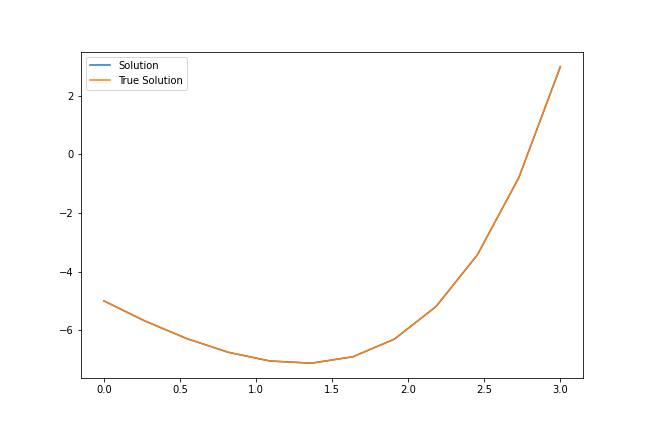

In [198]:
alpha = -5.0
beta = 3.0
L = 3.0
u_true = lambda x, alpha, beta, L: numpy.exp(x) + (beta - alpha + 1.0 - numpy.exp(L)) / L * x - 1.0 + alpha
x, U = high_order_differencing(10, lambda x: numpy.exp(x), alpha, beta, L)

fig = plt.figure(figsize=(9, 6))
plt.plot(x, U, label="Solution")
plt.plot(x, u_true(x, alpha, beta, L), label="True Solution")
plt.legend()
plt.show()


In [199]:
error = numpy.linalg.norm(U - u_true(x, alpha, beta, L), ord=numpy.infty)
print(error)
assert(error < 1e-3)
print("Success!")

0.00027681871107876344
Success!


**(b) Deferred Corrections:** [15] One way to obtain higher order results is to compute using a second order method but twice.  The first step is to compute the solution to the system
$$
    A U = F.
$$
Recall now that we know that the global error is defined as $E = U - \hat{U}$ and satisfies
$$
    A E = -\tau.
$$
We have an approximation to $\tau$ as
$$
    \tau_j = \frac{\Delta x^2}{12} u^{(4)}(x_j) + \mathcal{O}(\Delta x^4)
$$
which depends on the exact solution but we have already computed an approximation to that and can use an approximation to the fourth derivative of $U$ to compute $\tau$.  We can then solve the new system of equations and update the previous problem with the estimate of the global error we found.  

In general deferred correction methods solve the original problem at lower order and then use this solution to compute an estimate of the truncation error $\tau$, find the approximation of the global error $E$, and use this to update the solution.

For this question implement this method for $u''(x) = f(x)$ again.  Note that there may be a significant short cut assuming that the 4th derivative of $u(x)$ is smooth and using the original equation $u''(x) = f(x)$.  Another hint, this shortcut is very similar to the one we found for the 9-point Laplacian.  Do NOT assume that you know $f(x)$ before hand.

In [267]:
def deferred_correction(m, f, alpha, beta, L):
    """
    Solve u''(x) = f(x) using a deferred correction method
    
    :Input:
     - *m* (int) Number of points to use in the approximation (not including boundaries)
     - *f* (func) The right hand side function in the ODE
     - *alpha* (float) Left hand boundary condition u(0)
     - *beta* (float) Right hand boundary condition u(L)
     - *L* (float) Length of domain such that x \in [0, L]
     
    :Output:
     - *x* (ndarray) Points at which the solution is found AND the boundaries
     - *U* (ndarray) Solution at the x points and the boundaries.
    """
    # YOUR CODE HERE
    x_bc, U, mat = high_order_differencing(m, f, alpha, beta, L, True)
    # return x_bc, U
    h = x_bc[1] - x_bc[0]

    tau = np.concatenate([[0], [f(x_bc[i - 1]) - 2 * f(x_bc[i]) + f(x_bc[i + 1]) for i in range(1, len(U) - 1)] ,[0]])
    tau[0] = 2 * f(x_bc[0]) - 5 * f(x_bc[1]) + 4 * f(x_bc[2]) - f(x_bc[3])
    tau[-1] = -f(x_bc[-4]) + 4 * f(x_bc[-3]) - 5 * f(x_bc[-2]) + 2 * f(x_bc[-1])
    tau /= 12

    x_bc, U = high_order_differencing(m, lambda x: f(x) - tau[int(x / h)], alpha, beta, L)
    # E = linalg.spsolve(mat, -tau[1:-1])
    # U[1:-1] -= E
    # U4p = np.concatenate([[0, 0], [(U[i - 2] - 4 * U[i - 1] + 6 * U[i] - 4 * U[i + 1] + U[i + 2]) / (12 * h ** 4) for i in range(2, len(U) - 2)], [0, 0]])
    # for i in [0, 1]:
    #     U4p[i] = (3 * U[i] - 14 * U[i + 1] + 26 * U[i + 2] - 24 * U[i + 3] + 11 * U[i + 4] - 2 * U[i + 5]) / (12 * h ** 4) 
    # for i in [m, m + 1]:
    #     U4p[i] = (3 * U[i] - 14 * U[i - 1] + 26 * U[i - 2] - 24 * U[i - 3] + 11 * U[i - 4] - 2 * U[i - 5]) / (12 * h ** 4) 
    # E = linalg.spsolve(mat, -U4p[1:-1]) * h ** 2
    # U[1:-1] -= E
    return x_bc, U

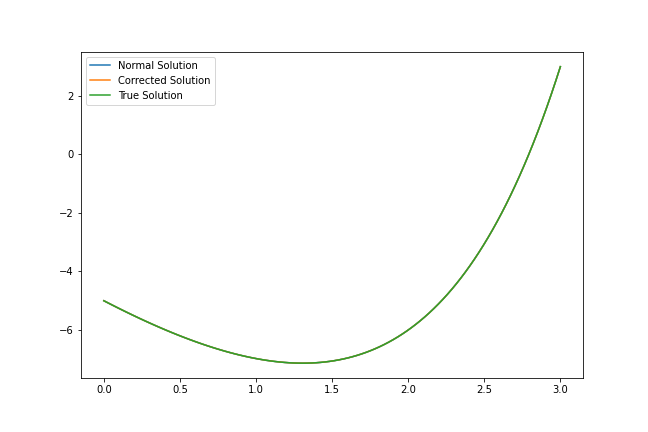

In [271]:
alpha = -5.0
beta = 3.0
L = 3.0
u_true = lambda x, alpha, beta, L: numpy.exp(x) + (beta - alpha + 1.0 - numpy.exp(L)) / L * x - 1.0 + alpha
x, U = high_order_differencing(100, lambda x: numpy.exp(x), alpha, beta, L)
x, U2 = deferred_correction(100, lambda x: numpy.exp(x), alpha, beta, L)

fig = plt.figure(figsize=(9, 6))
plt.plot(x, U, label="Normal Solution")
plt.plot(x, U2, label="Corrected Solution")
plt.plot(x, u_true(x, alpha, beta, L), label="True Solution")
plt.legend()
plt.show()

In [270]:
alpha = -5.0
beta = 3.0
L = 3.0
u_true = lambda x, alpha, beta, L: numpy.exp(x) + (beta - alpha + 1.0 - numpy.exp(L)) / L * x - 1.0 + alpha
x, U = deferred_correction(100, lambda x: numpy.exp(x), alpha, beta, L)
error = numpy.linalg.norm(U - u_true(x, alpha, beta, L), ord=numpy.infty)
print(error)
assert(error < 1e-3)
print("Success!")

0.00047050954970639935
Success!


**(c)** [5] Confirm the order of convergence for the two methods above.

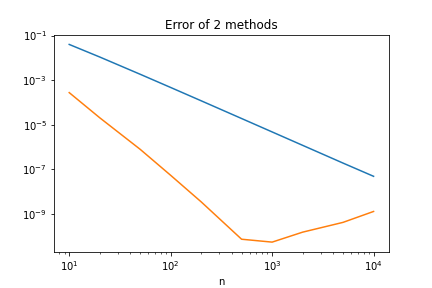

In [280]:
ks = [10, 20, 50, 100, 200, 500, 1000, 2000, 5000, 10000]
plt.figure()

for method in [deferred_correction, high_order_differencing]:
    errs = [0] * len(ks)
    for i in ks:
        x, U = method(i, lambda x: numpy.exp(x), alpha, beta, L)

        errs[ks.index(i)] = numpy.linalg.norm(U - u_true(x, alpha, beta, L), ord=numpy.infty)
    
    
    plt.plot(ks, errs)

plt.xscale('log')
plt.yscale('log')
plt.xlabel("n")
plt.title("Error of 2 methods")
plt.show()

As we can see from the graph, the two methods all converge linearly.